<a href="https://colab.research.google.com/github/sauravpatil045/MLOPS1.THIRD-YEAR/blob/main/MIL7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [141]:
#import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['figure.figsize'] = (6,5) #Default fig size
plt.rcParams['figure.dpi'] = 150 #Default fig resolution
sns.set_style('darkgrid') #Default diagram theme

In [142]:
df = pd.read_csv('Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [143]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [144]:
# Drop the unnecessary columns
df.drop(['CustomerID', 'Gender', 'Age'], axis=1, inplace=True)
df.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


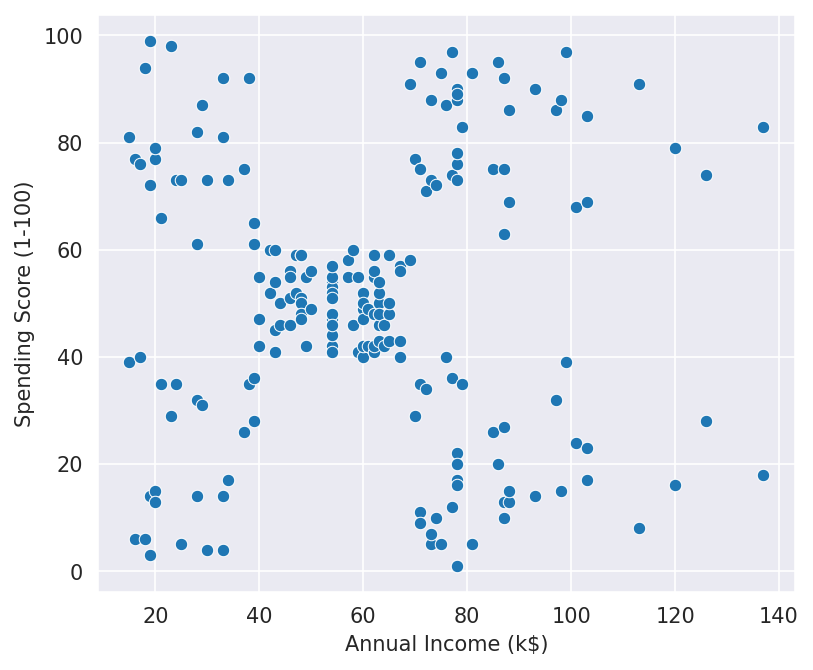

In [145]:
#Data visualization
sns.scatterplot(x=df['Annual Income (k$)'], y=df['Spending Score (1-100)'])
plt.show()

In [146]:
#Standardization
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x = sc.fit_transform(df)
x[:10]

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002]])

In [147]:
from sklearn.cluster import KMeans
km = KMeans()
yp = km.fit_predict(x)
yp

array([0, 4, 0, 4, 0, 4, 0, 4, 0, 4, 0, 4, 0, 4, 0, 4, 0, 4, 0, 4, 0, 4,
       0, 4, 0, 4, 0, 4, 0, 4, 0, 4, 0, 4, 0, 4, 0, 4, 0, 4, 6, 4, 6, 6,
       0, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 1, 6, 6, 1, 1, 6, 6, 6, 6,
       6, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 2, 7, 2, 7, 2,
       1, 2, 7, 2, 7, 2, 7, 2, 7, 2, 1, 2, 7, 2, 1, 2, 7, 2, 7, 2, 7, 2,
       7, 2, 7, 2, 7, 2, 1, 2, 7, 2, 7, 2, 7, 2, 7, 2, 7, 2, 7, 2, 7, 2,
       7, 2, 7, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5,
       3, 5], dtype=int32)

In [148]:
len(yp)

200

In [149]:
km.cluster_centers_

array([[-1.35185213, -1.19089759],
       [ 0.1206509 , -0.15673077],
       [ 0.66703804,  1.23036618],
       [ 1.87564575, -1.09476801],
       [-1.35366972,  1.15873115],
       [ 1.81769762,  1.26275949],
       [-0.50630013,  0.0469388 ],
       [ 0.7489536 , -1.45651437]])

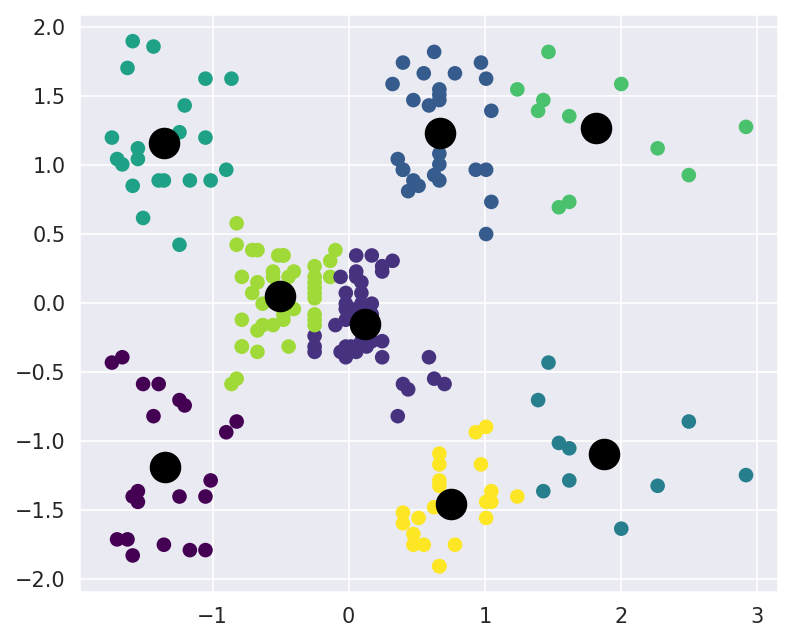

In [150]:
plt.scatter(x[:,0], x[:,1], c=yp, cmap="viridis")
plt.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1], c='black', s=200, marker='o')
plt.show()

In [151]:
km.inertia_

37.19778691869562

In [152]:
wcss = []
for i in range(1, 20):
    km = KMeans(n_clusters=i)
    km.fit_predict(x)
    wcss.append(km.inertia_)

In [153]:
wcss

[399.99999999999994,
 276.44878073832723,
 157.70400815035939,
 108.92131661364358,
 65.57885579985046,
 55.057348270385965,
 49.97805051988058,
 37.31912287833882,
 36.23314509613495,
 31.540767080967235,
 25.905865152509044,
 23.587112955683903,
 22.067709569853456,
 19.19701216148553,
 18.809401737367835,
 16.79685332191136,
 16.881091599897495,
 14.00035541944162,
 14.601373589898845]

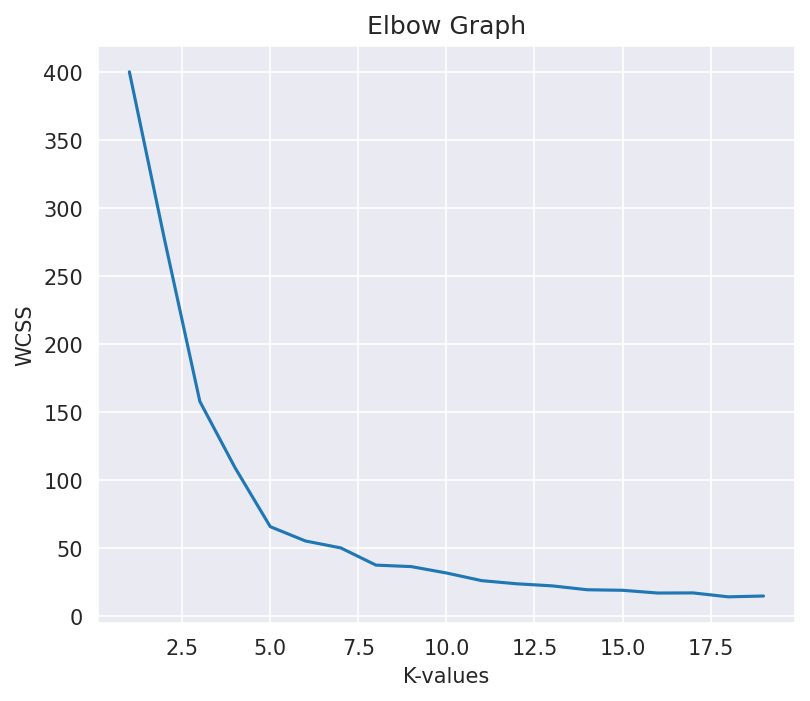

In [154]:
plt.plot(range(1,20),wcss)
plt.xlabel('K-values')
plt.ylabel('WCSS')
plt.title('Elbow Graph')
plt.show()

In [155]:
from sklearn.metrics import silhouette_score
silhouette_score(x,yp)

np.float64(0.45543473014577757)

K = 2, Silhouette Score = 0.321
K = 3, Silhouette Score = 0.467
K = 4, Silhouette Score = 0.494
K = 5, Silhouette Score = 0.555
K = 6, Silhouette Score = 0.540
K = 7, Silhouette Score = 0.528
K = 8, Silhouette Score = 0.455
K = 9, Silhouette Score = 0.457
K = 10, Silhouette Score = 0.443


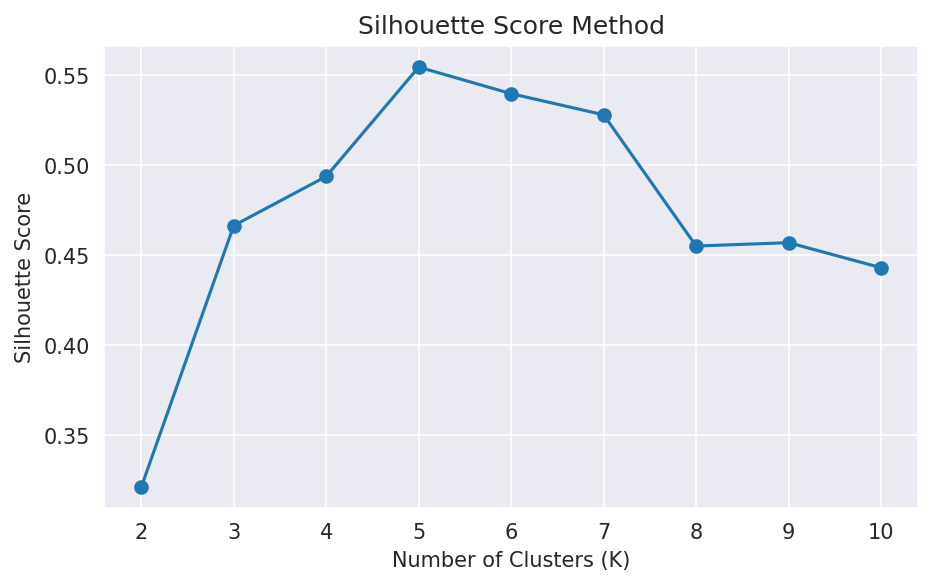

In [157]:
silhouette_scores = []
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(x)
    score = silhouette_score(x, labels)
    silhouette_scores.append(score)
    print(f"K = {k}, Silhouette Score = {score:.3f}")

# Visualize Silhouette Scores
plt.figure(figsize=(7, 4))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Silhouette Score Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()